## Comparison of obtained distributions to normal distribution

In [3]:
import scipy.stats as stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

For all tests scipy.stats.normaltest was used which implements D'Agostino and Pearson's test.

### Data loading time distributions

#### Histograms of time taken for each method to load data without buffer clearing

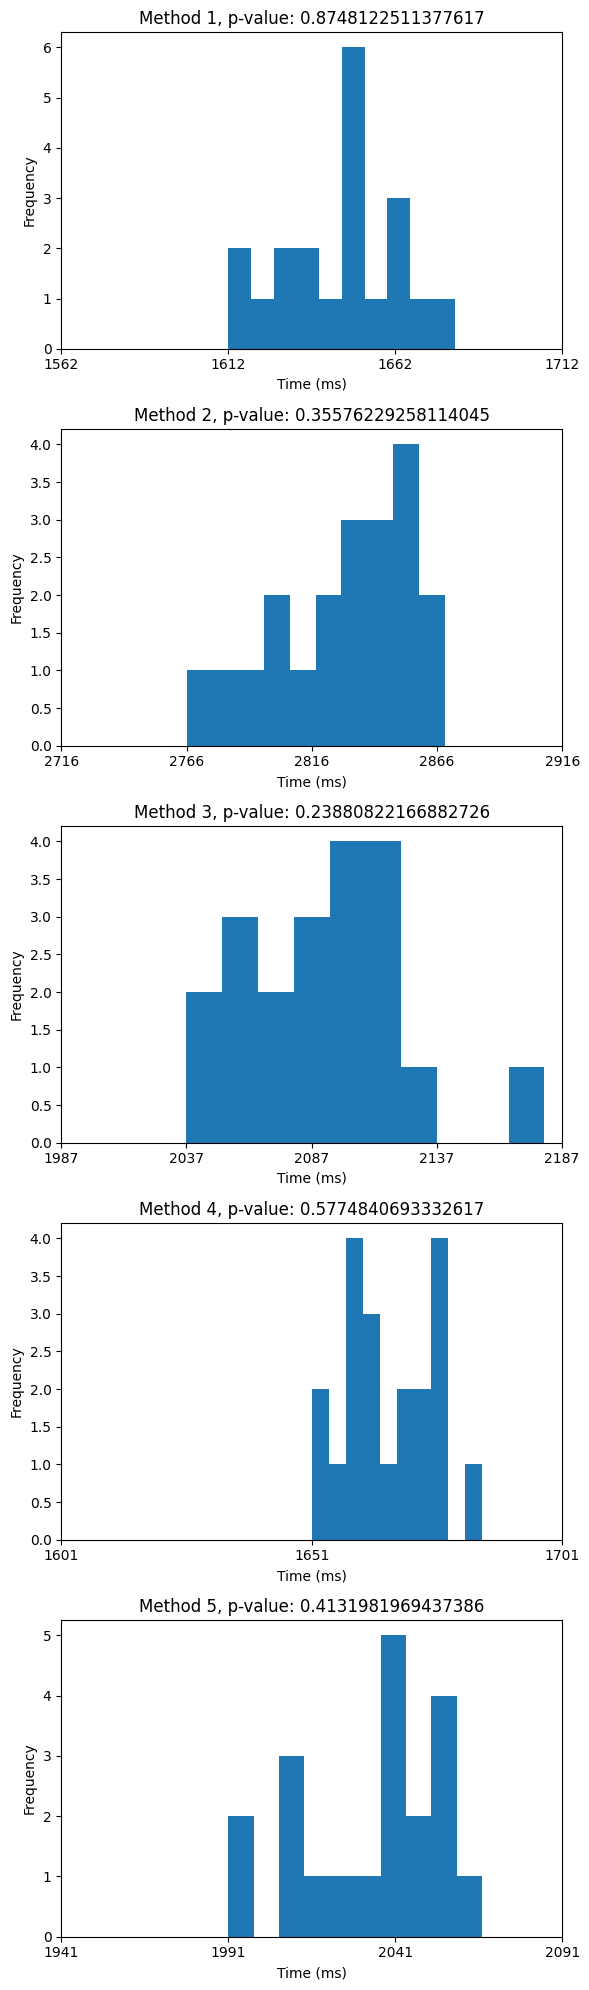

In [21]:
load_file_results = pd.read_csv('program1_results/results_50m_no_clearing.csv')
load_file_results = load_file_results.drop(columns=['Unnamed: 5'])
fig, ax = plt.subplots(len(load_file_results.columns), 1, figsize=(6, 20))
for i, column in enumerate(load_file_results.columns):
    ax[i].hist(load_file_results[column])
    ax[i].set_xticks(np.arange(np.min(load_file_results[column])-50, np.max(load_file_results[column])+50,50))
    ax[i].set_xlabel("Time (ms)")
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(f"Method {i+1}, p-value: {stats.normaltest(load_file_results[column])[1]}")
fig.tight_layout()
plt.show()

#### Histograms of time taken for each method to load data with buffers cleared

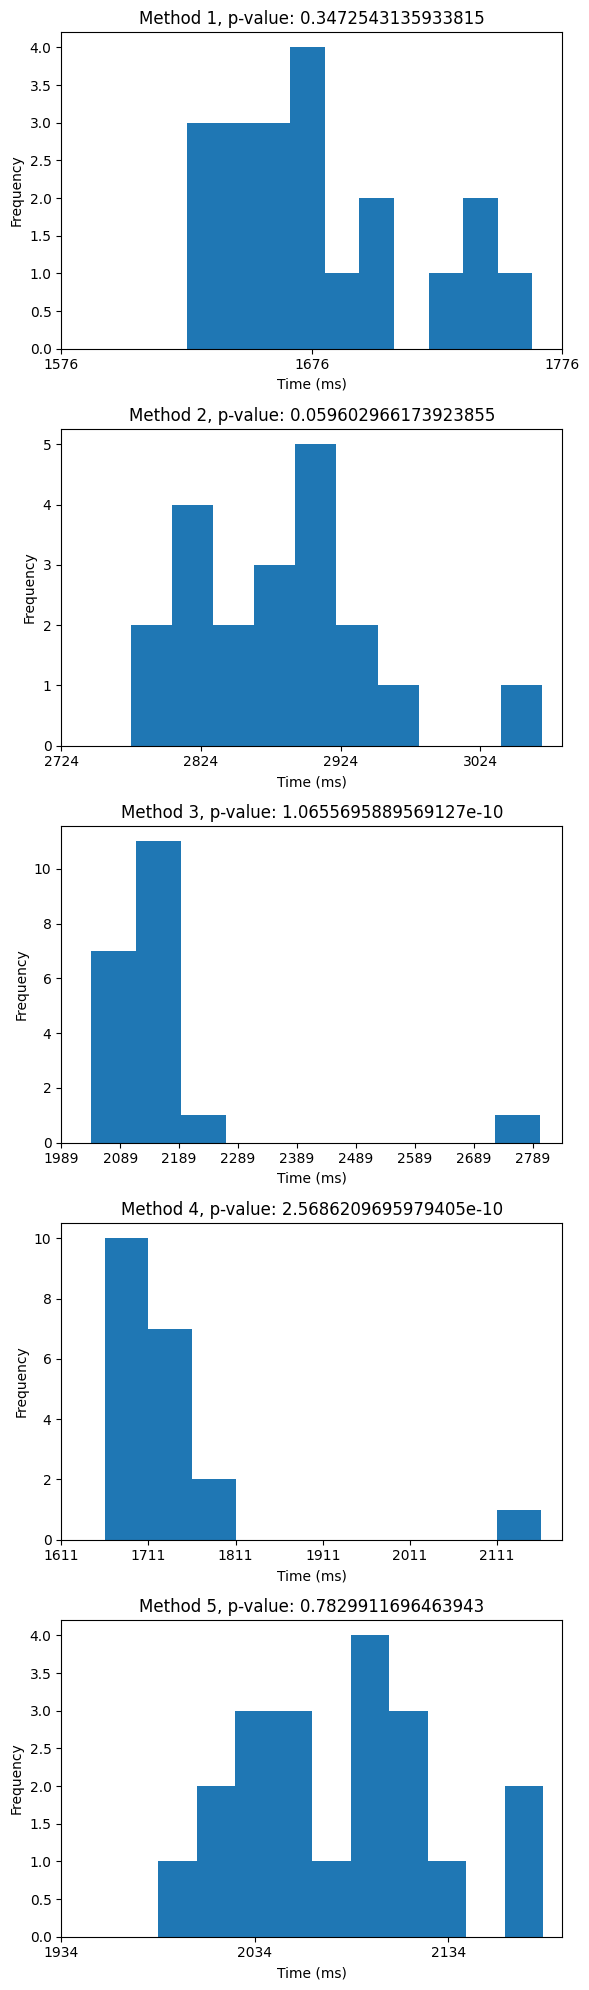

In [34]:
load_file_results = pd.read_csv('program1_results/results_50m_with_clearing.csv')
load_file_results = load_file_results.drop(columns=['Unnamed: 5'])
fig, ax = plt.subplots(len(load_file_results.columns), 1, figsize=(6, 20))
for i, column in enumerate(load_file_results.columns):
    ax[i].hist(load_file_results[column])
    ax[i].set_xticks(np.arange(np.min(load_file_results[column])-50, np.max(load_file_results[column])+50,100))
    ax[i].set_xlabel("Time (ms)")
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(f"Method {i+1}, p-value: {stats.normaltest(load_file_results[column])[1]}")
fig.tight_layout()
plt.show()

In case of cleared buffers, two methods (3 and 4) had significant outliers, causing low p-values, though without them the distributions would be seemingly close to normal. In method 2, same happens, but outlier is close to the main group and the p-value is almost 0.05 which I would say is enough to consider the distribution not normal.

Overall, most methods during their 20 runs had distributions close to normal with rare outliers that were close to the main group if appearing.

### Data conversion time distributions

/home/kuzmarg/Documents/UCU/ACS/lab1-productivity-valihurskyi_shrtohryn_kuzma/.env/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


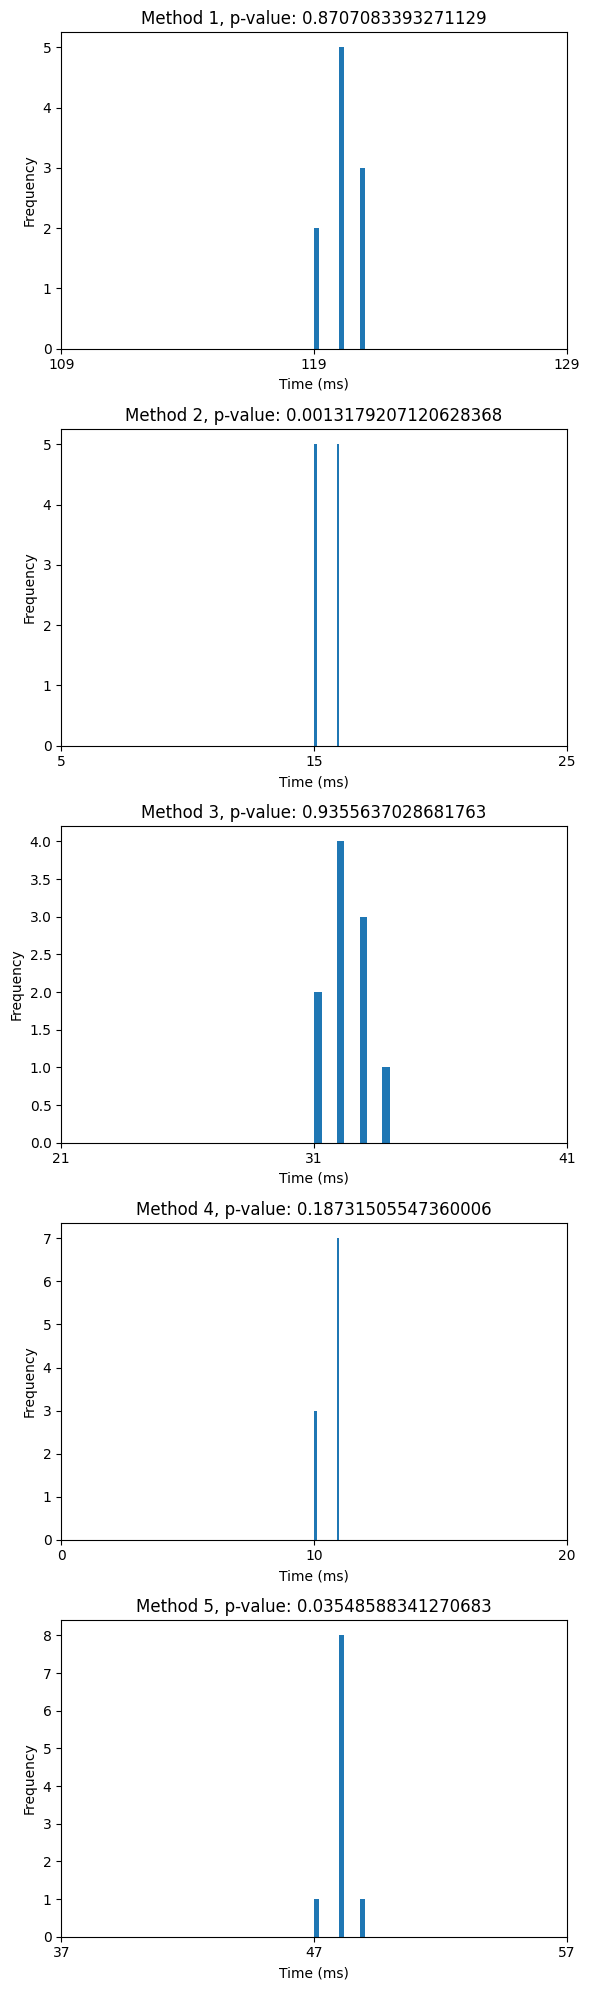

In [27]:
load_file_results = pd.read_csv('program2_results/results/1m_clean_res.csv')
load_file_results = load_file_results.drop(columns=['Unnamed: 5'])
fig, ax = plt.subplots(len(load_file_results.columns), 1, figsize=(6, 20))
for i, column in enumerate(load_file_results.columns):
    ax[i].hist(load_file_results[column])
    ax[i].set_xticks(np.arange(np.min(load_file_results[column])-10, np.max(load_file_results[column])+10,10))
    ax[i].set_xlabel("Time (ms)")
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(f"Method {i+1}, p-value: {stats.normaltest(load_file_results[column])[1]}")
fig.tight_layout()
plt.show()

In this case, it seems that the sample sizes were simply too small for adequate testing. In most cases the p-values were high, indicating distributions close to normal, but visually and considering the sample size, I would not trust these results.

### Splitting time distributions

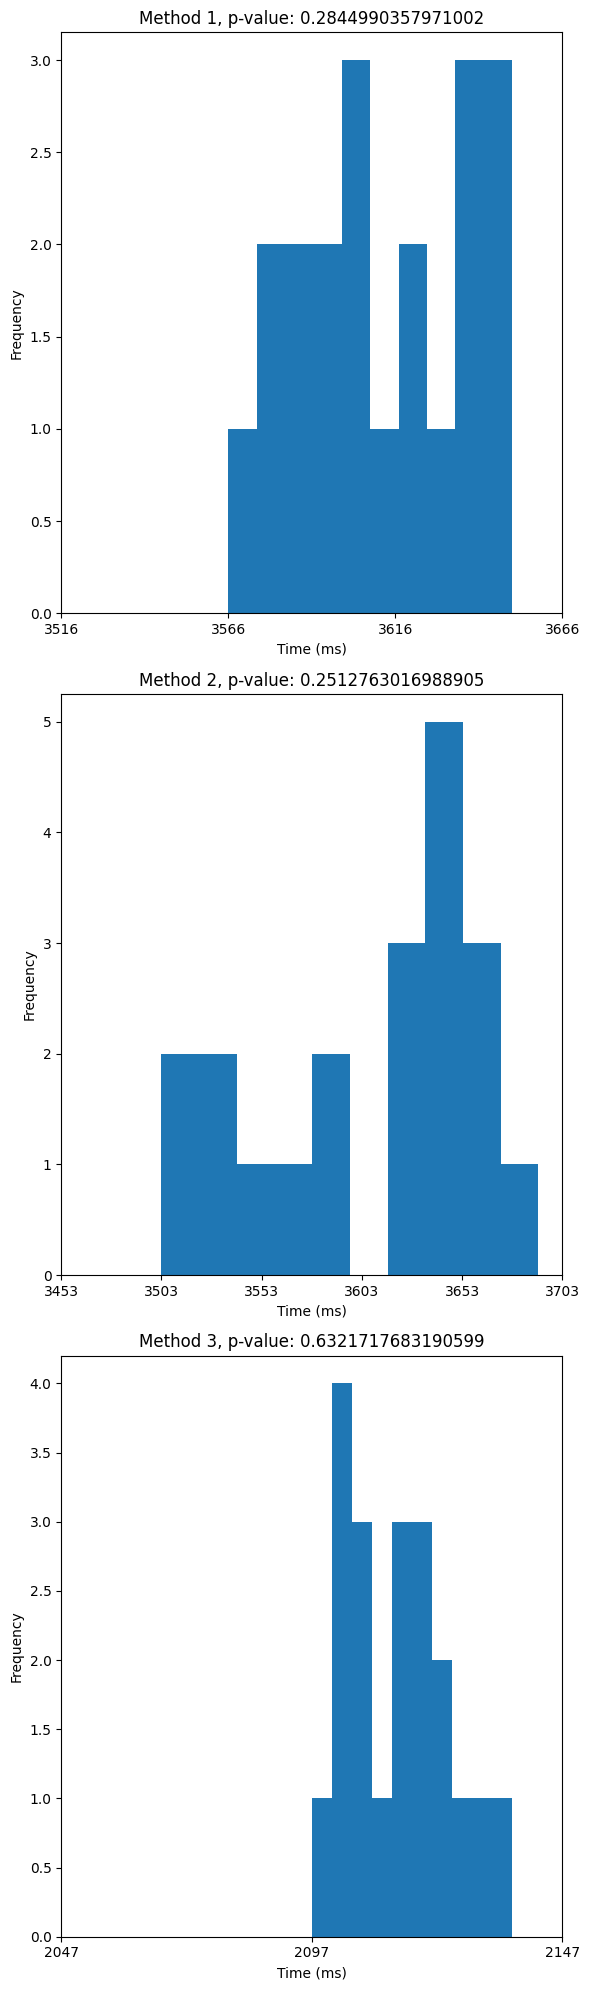

In [31]:
load_file_results = pd.read_csv('bonus1_results/split_results.csv', names=['1', '2', '3'])
fig, ax = plt.subplots(len(load_file_results.columns), 1, figsize=(6, 20))
for i, column in enumerate(load_file_results.columns):
    ax[i].hist(load_file_results[column])
    ax[i].set_xticks(np.arange(np.min(load_file_results[column])-50, np.max(load_file_results[column])+50,50))
    ax[i].set_xlabel("Time (ms)")
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(f"Method {i+1}, p-value: {stats.normaltest(load_file_results[column])[1]}")
fig.tight_layout()
plt.show()

In this case, for splitting methods the sample sizes were larger and the tests more reliable. P-values are quire high and visually there are no significant right outliers on the histograms, as were seen before. Overall, data is close to normal.

### Data conversion time distributions (bonus methods)

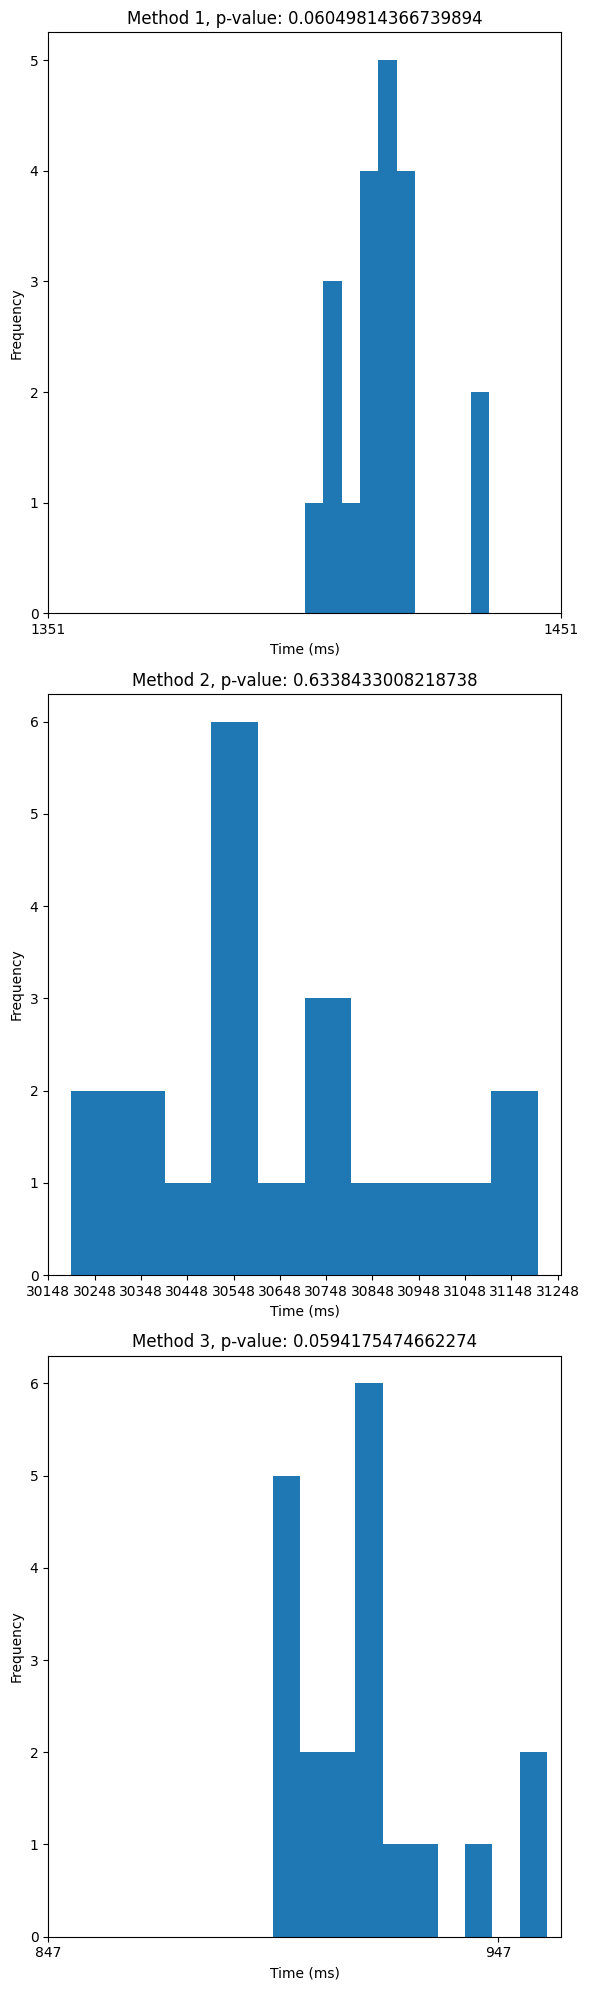

In [33]:
load_file_results = pd.read_csv('bonus1_results/convert_results.csv', names=['1', '2', '3'])
fig, ax = plt.subplots(len(load_file_results.columns), 1, figsize=(6, 20))
for i, column in enumerate(load_file_results.columns):
    ax[i].hist(load_file_results[column])
    ax[i].set_xticks(np.arange(np.min(load_file_results[column])-50, np.max(load_file_results[column])+50,100))
    ax[i].set_xlabel("Time (ms)")
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(f"Method {i+1}, p-value: {stats.normaltest(load_file_results[column])[1]}")
fig.tight_layout()
plt.show()

Finally, in this case all p-values were higher than 0.05, but two were very close, indicating that the distributions vary from normal significantly. Visually, it can be seen once again as right skewness in the histograms.

**Overall, most of the observed runs had distributions close to normal, but an interesting observation is that cases with low p-value were almost always explained by right skewness in the histograms, meaning that the time distributions for the algorithms tend to have outliers that are significantly slower than the rest of the runs (most likely due to external factors of the OS that test was run on). Therefore, we still can with some confidence say that distributions can be treated as normal, but have to keep in mind that outliers have to be cleaned before any analysis that assumes normality.**